In [6]:
!pip3 install numpy scipy matplotlib

In [1]:
import numpy as np
from scipy.stats import binom, norm, poisson
import matplotlib.pyplot as plt

## 1. Биномиальное распределение

In [2]:
# Задаем функции для вычисления P(S_n = k) биномиального распределения

# Точное значение вероятности
# P(S_n = k) = C_{n}^{k} * p^{k} * (1 - p)^{k}
def binom_exact_prob(k, n, p):
    return binom.pmf(k, n, p)

# Приближение значением распределения Пуассона
# lambda = np
def binom_poisson_prob(k, n, p):
    return poisson.pmf(k, mu=n * p)

# Приближение с помощью нормального распределения
# По теореме Муавра-Лапласа
def binom_moivre_laplace(k, n, p):
    mu = n * p
    sigma = np.sqrt(n * p * (1 - p))
    return norm.pdf(k, loc=mu, scale=sigma)

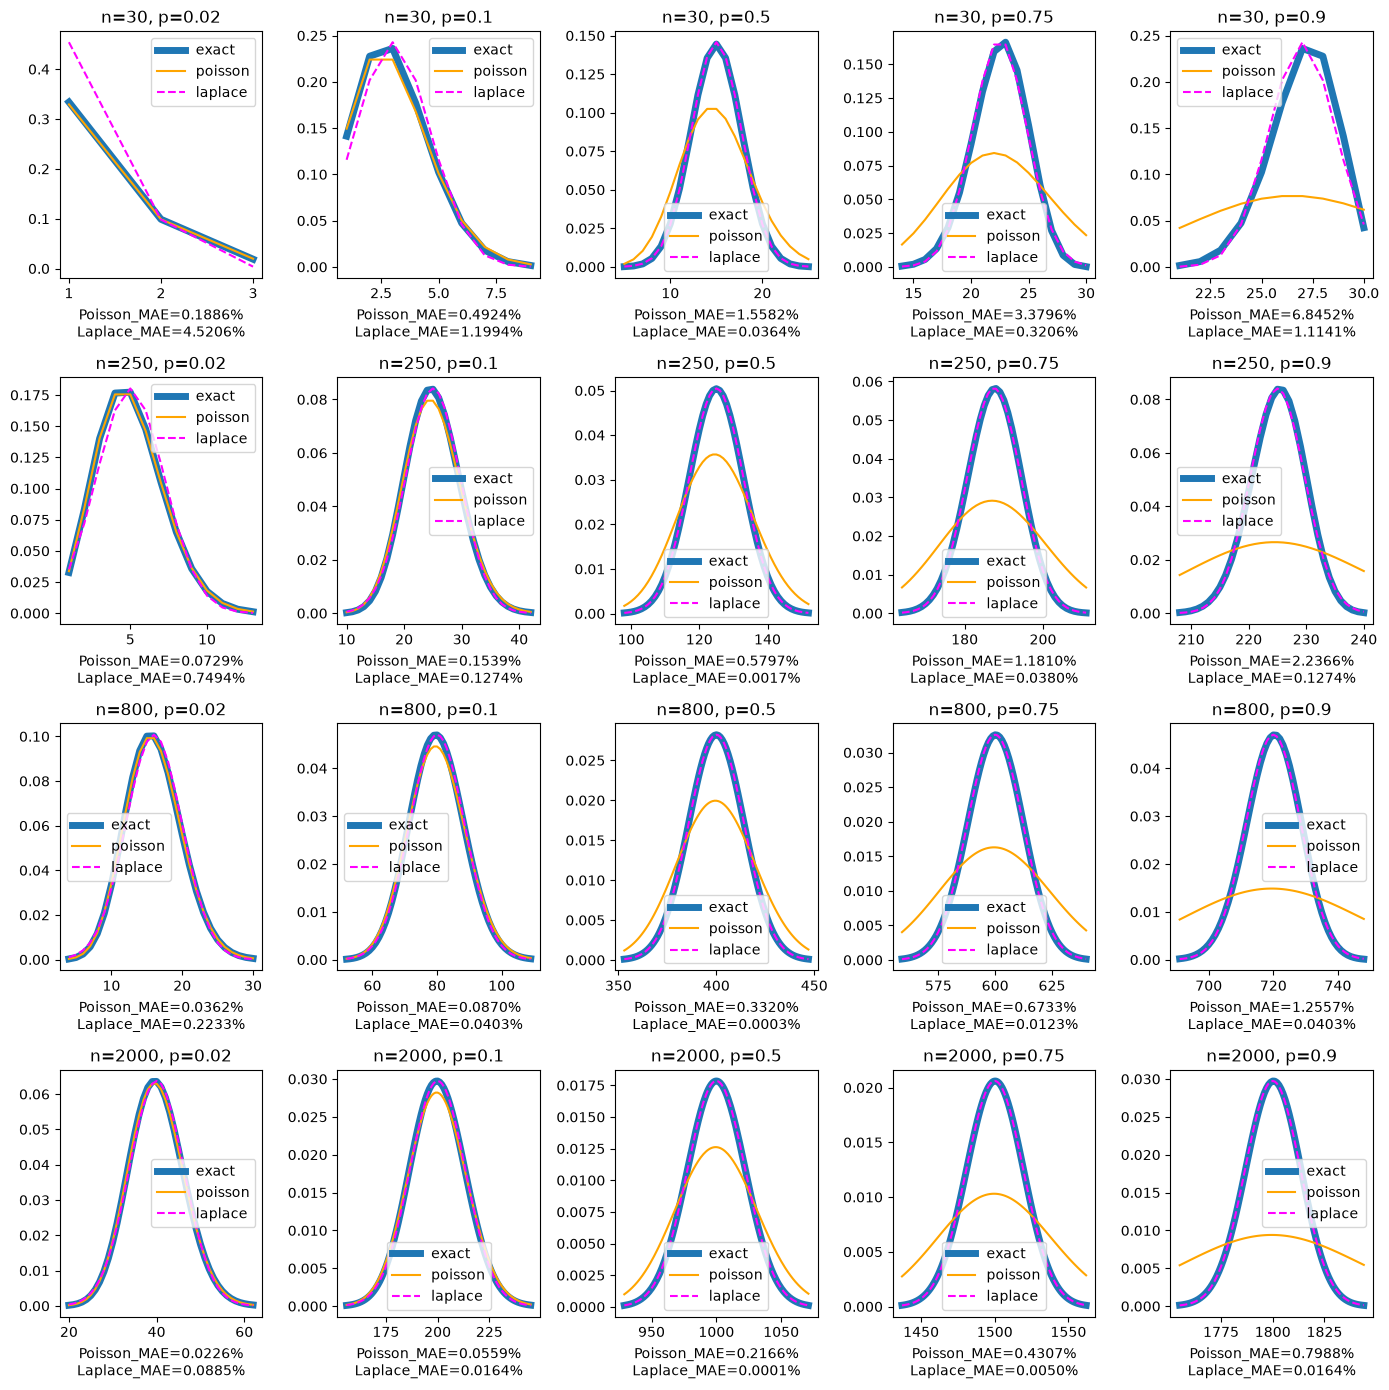

In [3]:
# Посмотрим на графики распределения и посчитаем MAE (mean absolute error) в %

# Различные значения параметров, которые будем перебирать
# Будем считать со всеми k in [1:n]

# по вертикали -- количество экспериментов
ns = [30, 250, 800, 2000]

# по горизонтали -- вероятность "успешного" исхода
ps = [0.02, 0.1, 0.5, 0.75, 0.9]

# Помогает отрезать ненужную часть графика, где у всех распределений
# значение примерно 0. use_threshold=False отключает обрезание
threshold = 1e-4
use_threshold = True

fig, axes = plt.subplots(len(ns), len(ps), figsize=(14, 14))

for i, n in enumerate(ns):
    for j, p in enumerate(ps):
        ax = axes[i, j]
        ks = np.arange(1, n + 1)
        exact = binom_exact_prob(ks, n, p)
        poiss = binom_poisson_prob(ks, n, p)
        lapl = binom_moivre_laplace(ks, n, p)

        using_threshold = threshold if use_threshold else 0
        mask = (exact > using_threshold) & (poiss > using_threshold) & (lapl > using_threshold)

        poisson_mae = np.abs(poiss[mask] - exact[mask]).mean() * 100
        lapl_mae = np.abs(lapl[mask] - exact[mask]).mean() * 100

        ax.plot(ks[mask], exact[mask], label="exact", linewidth=5)
        ax.plot(ks[mask], poiss[mask], color='orange', label="poisson")
        ax.plot(ks[mask], lapl[mask], color='magenta', label="laplace", linestyle="--")

        ax.set_title(f"n={n}, p={p}")
        ax.set_xlabel(f"Poisson_MAE={poisson_mae:.4f}%\nLaplace_MAE={lapl_mae:.4f}%")
        ax.legend()

plt.tight_layout()
plt.show()

По диаграмме видно следующее:
1) График приближения с помощью нормального распределения по локальной теореме Муавра-Лапласа довольно хорошо ложится на график точного биномиального распределения
2) Распределение Пуассона лучше подходит в случае малого p, при большом оно сильно расходится с другими графиками

## 2. Гипергеометрическое распределение

Имеем следующее утверждение:

![из учебника](./hyperheom.png)

Поэтому посмотрим, как можно аппроксимировать гипергеометрическое распределение с помощью уже сделанных приближений для биномиального

In [4]:
from scipy.stats import hypergeom

# Гипергеометрическое распределение

"""
whole -- общее количество "шаров"
whole_marked -- количество помеченных "шаров"
take -- размер выборки
expect_marked -- сколько, как мы ожидаем, будет помеченных "шаров" в выборке
"""

# Точная формула
def hyperheom_exact(whole, whole_marked, take, expect_marked):
    return hypergeom.pmf(expect_marked, whole, whole_marked, take)

# Приближение с помощью точной формулы для биномиального распределения 
def hyperheom_binom(whole, whole_marked, take, expect_marked):
    return binom_exact_prob(expect_marked, take, whole_marked / whole)

# Приближение с помощью распределения Пуассона
def hyperheom_binom_poisson(whole, whole_marked, take, expect_marked):
    return binom_poisson_prob(expect_marked, take, whole_marked / whole)

# Распределение с помощью нормального распределения по теореме Муавра-Лапласа
def hyperheom_binom_moivre_laplace(whole, whole_marked, take, expect_marked):
    return binom_moivre_laplace(expect_marked, take, whole_marked / whole)

In [5]:
def measure_hypergeom(p, K=50):
    params = []

    for i in range(3):
        params.append((K * 10 ** i, K * 10 ** i * p))

    take_coefs = [0.05, 0.2, 0.5, 0.8]
    threshold = 1e-4

    fig, axes = plt.subplots(len(params), len(take_coefs), figsize=(14, 10))

    for i, (whole, whole_marked) in enumerate(params):
        for j, take_coef in enumerate(take_coefs):

            take = int(take_coef * whole)

            ax = axes[i, j]
            ks = np.arange(0, take + 1)
            exact = hyperheom_exact(whole, whole_marked, take, ks)
            binom_approx = hyperheom_binom(whole, whole_marked, take, ks)
            poiss = hyperheom_binom_poisson(whole, whole_marked, take, ks)
            lapl = hyperheom_binom_moivre_laplace(whole, whole_marked, take, ks)

            mask = (exact > threshold) & (binom_approx > threshold) & (poiss > threshold) & (lapl > threshold)

            binom_mae = np.abs(binom_approx[mask] - exact[mask]).mean() * 100
            poisson_mae = np.abs(poiss[mask] - exact[mask]).mean() * 100
            lapl_mae = np.abs(lapl[mask] - exact[mask]).mean() * 100

            ax.plot(ks[mask], exact[mask], label="exact", linewidth=2.5)
            ax.plot(ks[mask], binom_approx[mask], label="binom", linestyle="--")
            ax.plot(ks[mask], poiss[mask], label="poisson", linestyle="dotted")
            ax.plot(ks[mask], lapl[mask], label="laplace", linestyle="dashdot")

            ax.set_title(f"W={whole}, P={whole_marked/whole*100:.0f}, T={take}")
            ax.set_xlabel(f"Poisson_MAE={poisson_mae:.4f}%\nLaplace_MAE={lapl_mae:.4f}%\nBinom_MAE={binom_mae:4f}%")
            ax.legend(fontsize=6)

    plt.tight_layout()
    plt.show()

In [6]:
# Сделаем то же самое, только теперь по вертикали будем перебирать наборы (whole, whole_marked)
# по горизонтали -- take_coef. Рассчитываем take = take_coef * whole

# при этом сохраняем условие того, что whole_marked/whole -> P (при whole -> +oo)

# посмотрим разные P: 0.1, 0.5, 0.9

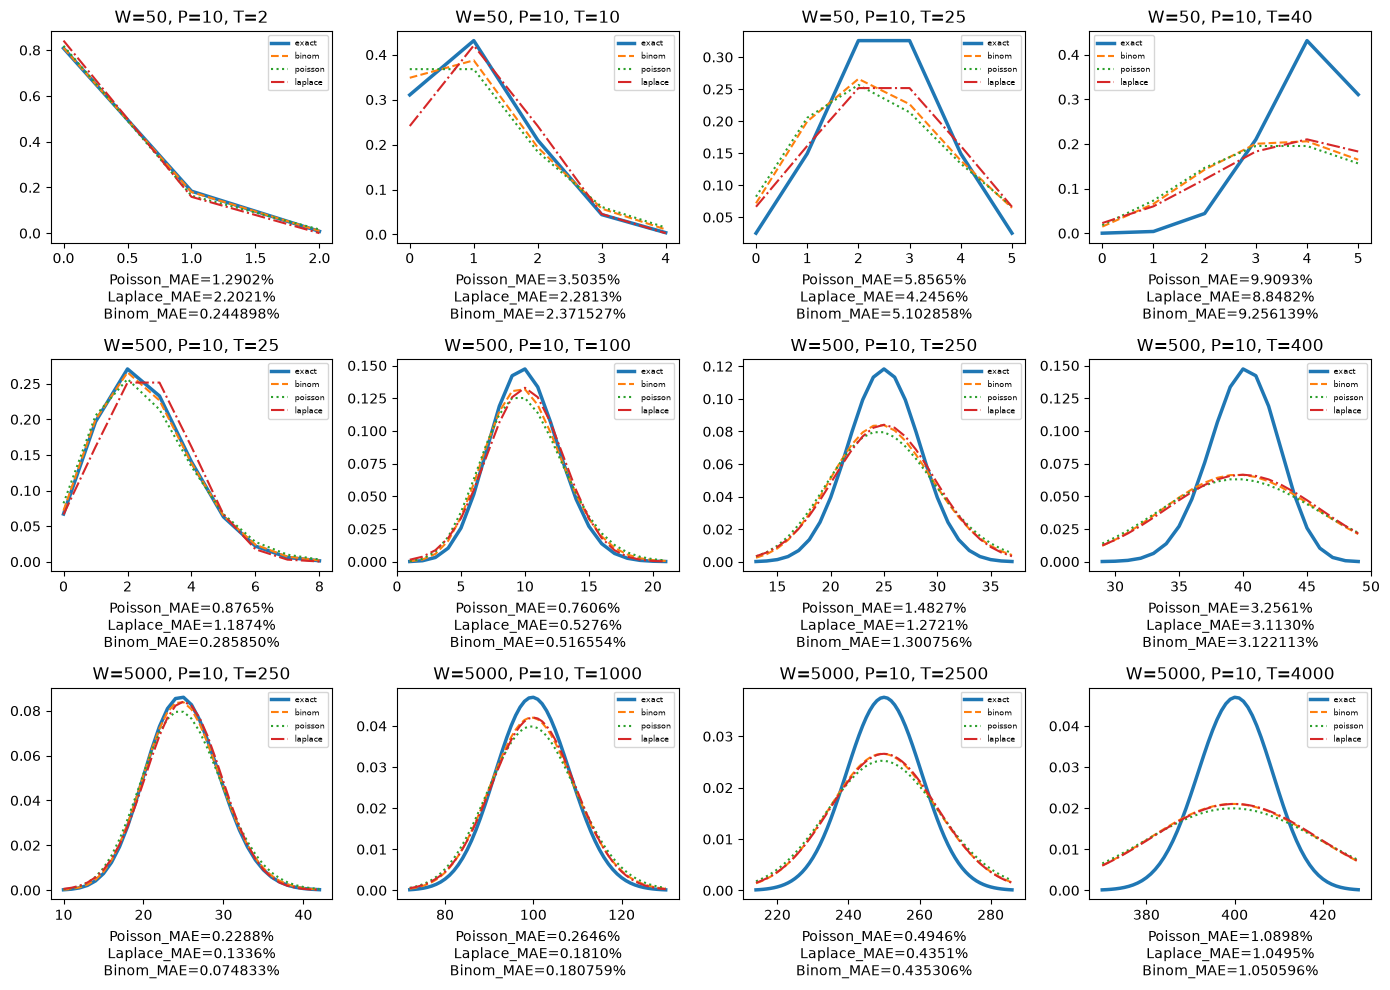

In [7]:
measure_hypergeom(0.1)

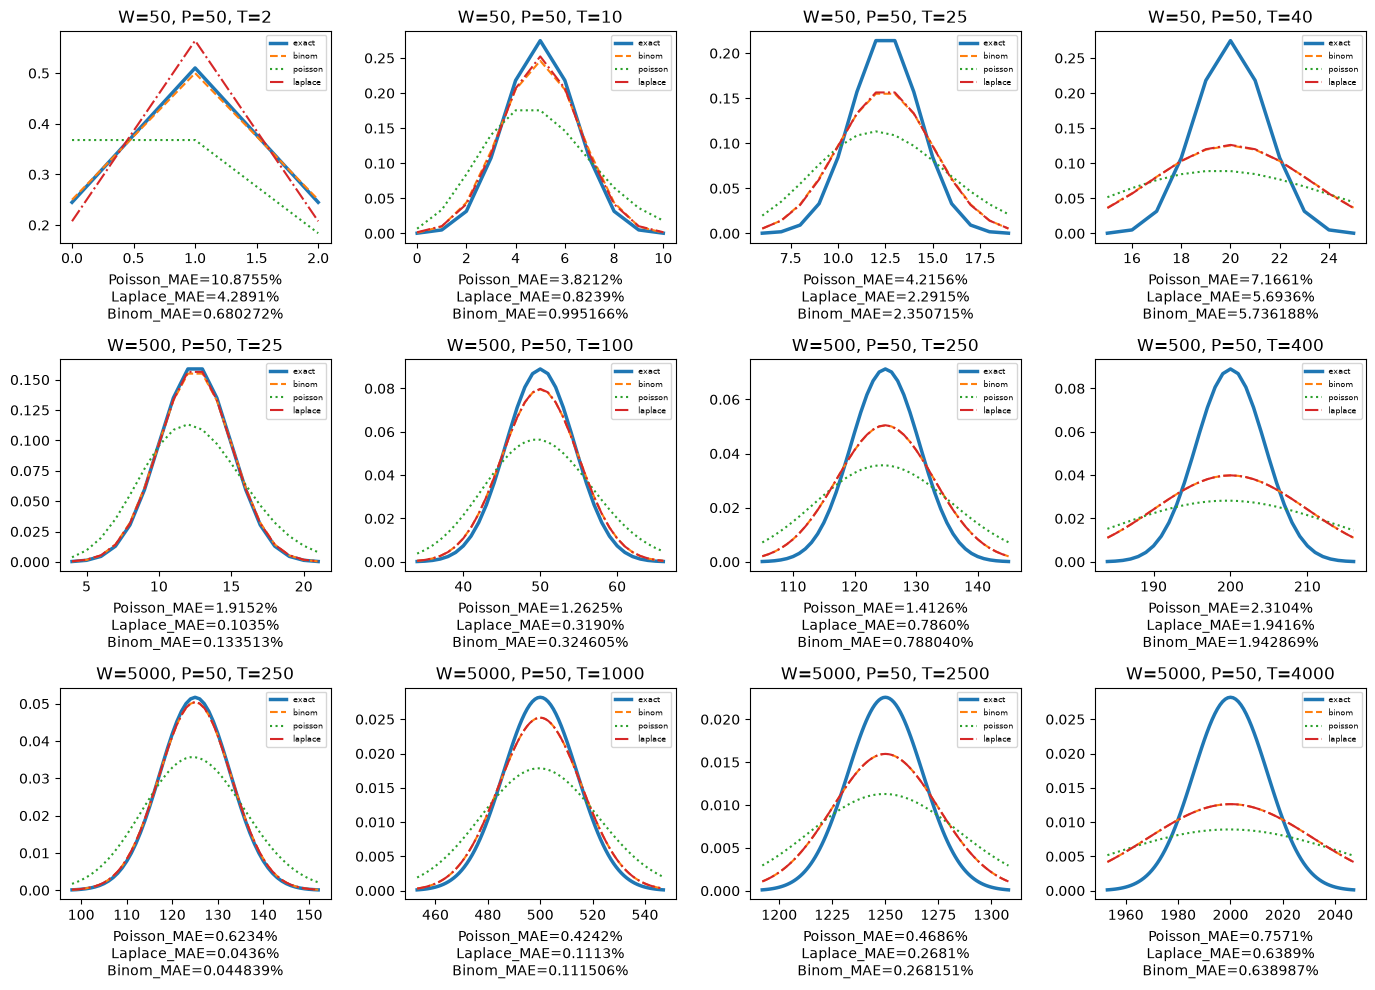

In [8]:
measure_hypergeom(0.5)

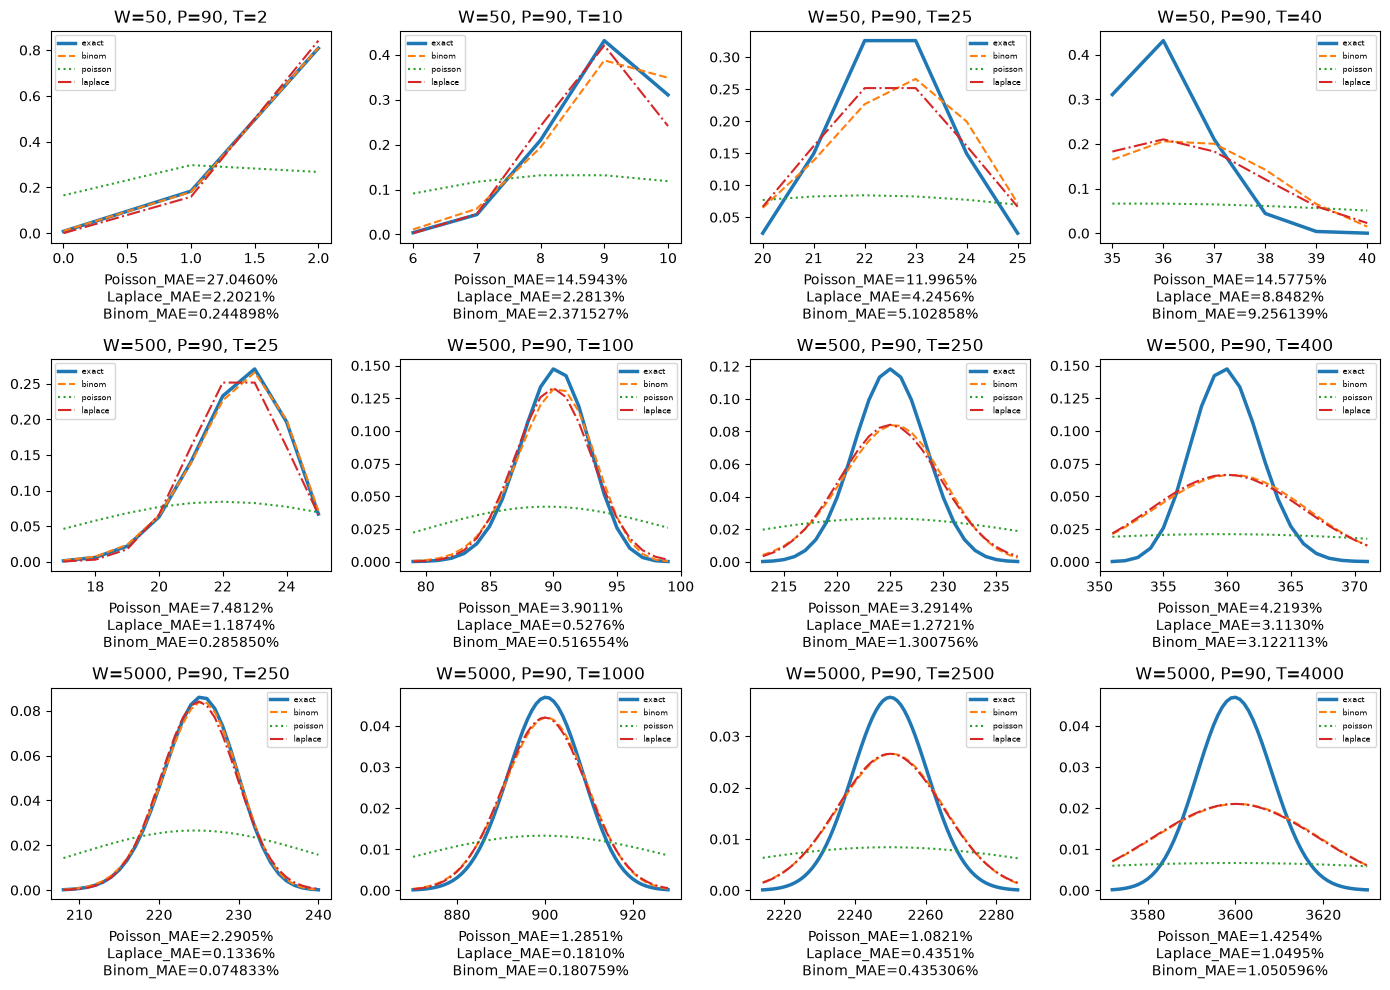

In [9]:
measure_hypergeom(0.9)

Из диаграмм можем сделать выводы:
1) Все приближения становятся сильно хуже, когда take_coef становится очень большим. Это и логично: приближение должно работать, когда без возвращения "шаров" обратно вероятность вытащить помеченный меняется очень мало. А тут мы вытаскиваем значимую долю всех шаров, поэтому эта вероятность может сильно поменяться
2) Распределение Пуассона очень плохо приближает гипергеометрическое при больших P, но это следует из того, что оно плохо приближает биномиальное при таких P (см. прошлый пункт)